Adding the first code cell

In [12]:
import torch
import anomalib

print("Anomalib version:", anomalib.__version__)
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

Anomalib version: 2.7.0
PyTorch version: 2.14.1
MPS available: True


Configuring the MVTec bottle dataset

In [13]:

from pathlib import Path

import torch
from anomalib.data import Folder
from anomalib.models import Patchcore
from anomalib.engine import Engine

# Project paths
PROJECT_ROOT = Path.home() / "Projects" / "VisionQC"
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "mvtec-ad" / "bottle"

print("Dataset root:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())


Dataset root: /Users/anupamguptaroy17/Projects/VisionQC/data/raw/mvtec-ad/bottle
Dataset exists: True


Setting up the PatchCore data module

In [14]:
from anomalib.data import Folder

normal_train_dir = DATA_ROOT / "train" / "good"
normal_test_dir = DATA_ROOT / "test" / "good"

abnormal_dirs = [
    DATA_ROOT / "test" / "broken_small",
    DATA_ROOT / "test" / "broken_large",
    DATA_ROOT / "test" / "contamination",
]

mask_dirs = [
    DATA_ROOT / "ground_truth" / "broken_small",
    DATA_ROOT / "ground_truth" / "broken_large",
    DATA_ROOT / "ground_truth" / "contamination",
]

datamodule = Folder(
    name="VisionQC_Bottle",
    root=DATA_ROOT,
    normal_dir=normal_train_dir,
    normal_test_dir=normal_test_dir,
    abnormal_dir=abnormal_dirs,
    mask_dir=mask_dirs,
    extensions=(".png",),
    train_batch_size=8,
    eval_batch_size=8,
    num_workers=0,
    normal_split_ratio=0,
    seed=42,
)

datamodule.setup()

print("Data module setup complete.")

Data module setup complete.


Inspecting a batch

In [15]:
train_batch = next(iter(datamodule.train_dataloader()))

print("Batch keys:", train_batch.keys())
print("Image shape:", train_batch["image"].shape)
print("Image dtype:", train_batch["image"].dtype)
print("Image range:", train_batch["image"].min().item(),
      "to", train_batch["image"].max().item())

Batch keys: ['image', 'gt_label', 'gt_mask', 'mask_path', 'anomaly_map', 'pred_score', 'pred_mask', 'pred_label', 'explanation', 'image_path']
Image shape: torch.Size([8, 3, 900, 900])
Image dtype: torch.float32
Image range: 0.09803922474384308 to 1.0


Resizing images to 256 x 256

In [16]:
import inspect
from anomalib.data import Folder

print(inspect.signature(Folder))

(name: str, normal_dir: str | pathlib.Path | collections.abc.Sequence[str | pathlib.Path], root: str | pathlib.Path | None = None, abnormal_dir: str | pathlib.Path | collections.abc.Sequence[str | pathlib.Path] | None = None, normal_test_dir: str | pathlib.Path | collections.abc.Sequence[str | pathlib.Path] | None = None, mask_dir: str | pathlib.Path | collections.abc.Sequence[str | pathlib.Path] | None = None, normal_split_ratio: float = 0.2, extensions: tuple[str] | None = None, train_batch_size: int = 32, eval_batch_size: int = 32, num_workers: int = 8, train_augmentations: torchvision.transforms.v2._transform.Transform | None = None, val_augmentations: torchvision.transforms.v2._transform.Transform | None = None, test_augmentations: torchvision.transforms.v2._transform.Transform | None = None, augmentations: torchvision.transforms.v2._transform.Transform | None = None, test_split_mode: anomalib.data.utils.split.TestSplitMode | str = <TestSplitMode.FROM_DIR: 'from_dir'>, test_split_

In [17]:
from torchvision.transforms import v2

resize_transform = v2.Resize((256, 256))

datamodule = Folder(
    name="VisionQC_Bottle",
    root=DATA_ROOT,
    normal_dir=normal_train_dir,
    normal_test_dir=normal_test_dir,
    abnormal_dir=abnormal_dirs,
    mask_dir=mask_dirs,
    extensions=(".png",),
    augmentations=resize_transform,
    train_batch_size=8,
    eval_batch_size=8,
    num_workers=0,
    normal_split_ratio=0,
    seed=42,
)

datamodule.setup()

train_batch = next(iter(datamodule.train_dataloader()))

print("Image shape:", train_batch["image"].shape)
print("Mask shape:", train_batch["gt_mask"].shape)

Image shape: torch.Size([8, 3, 256, 256])
Mask shape: torch.Size([8, 256, 256])


Initializing the PatchCore

In [18]:
from anomalib.models import Patchcore
from anomalib.engine import Engine

model = Patchcore(
    backbone="wide_resnet50_2",
    layers=["layer2", "layer3"],
    num_neighbors=6,
)

engine = Engine(
    max_epochs=1,
    accelerator="auto",
    devices=1,
)

print("PatchCore model initialized.")

PatchCore model initialized.


Fiting PatchCore

In [19]:
from lightning.pytorch.callbacks import TQDMProgressBar
from anomalib.engine import Engine

engine = Engine(
    max_epochs=1,
    accelerator="mps",
    devices=1,
    logger=False,
    callbacks=[TQDMProgressBar()],
)

print("Engine recreated with explicit TQDM progress bar.")

Engine recreated with explicit TQDM progress bar.


In [20]:
engine.fit(
    model=model,
    datamodule=datamodule,
)

print("PatchCore fitting complete.")

# import inspect
# from anomalib.engine import Engine

# print(inspect.signature(Engine))

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 24.9 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 24.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.9 M                                                                                               
Total estimated model params size (MB): 99.450                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 174                                                                                          
Total FLOPs: 0

/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/py

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

PatchCore fitting complete.


Verifying that PatchCore is fitted

In [21]:
print("Fitted flag:", model._is_fitted)
print("Memory bank shape:", model.model.memory_bank.shape)
print("Memory bank size (GB):",
      model.model.memory_bank.numel()
      * model.model.memory_bank.element_size() / 1e9)

Fitted flag: tensor([True])
Memory bank shape: torch.Size([21401, 1536])
Memory bank size (GB): 0.131487744


Running the PatchCore evaluation

In [22]:
results = engine.test(
    model=model,
    datamodule=datamodule,
)

print("PatchCore evaluation complete.")

The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │            1.0            │
│       image_F1Score       │            1.0            │
│        pixel_AUROC        │    0.9844614267349243     │
│       pixel_F1Score       │    0.7205246686935425     │
└───────────────────────────┴───────────────────────────┘

PatchCore evaluation complete.


Inspecting the PatchCore Predictions

In [24]:
print("Batch fields:", test_batch.keys())
print("Image shape:", test_batch["image"].shape)
print("Ground-truth label shape:", test_batch["gt_label"].shape)
print("Ground-truth mask shape:", test_batch["gt_mask"].shape)

NameError: name 'test_batch' is not defined

In [25]:
predictions = engine.predict(
    model=model,
    datamodule=datamodule,
)

print("Prediction batches:", len(predictions))
print("First prediction type:", type(predictions[0]))
print("First prediction fields:", predictions[0].keys())

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
/Users/anupamguptaroy17/Projects/VisionQC/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

Prediction batches: 6
First prediction type: <class 'anomalib.data.dataclasses.torch.image.ImageBatch'>
First prediction fields: ['image', 'gt_label', 'gt_mask', 'mask_path', 'anomaly_map', 'pred_score', 'pred_mask', 'pred_label', 'explanation', 'image_path']


In [26]:
first_prediction = predictions[0]

print("Image shape:", first_prediction.image.shape)
print("Ground-truth mask shape:", first_prediction.gt_mask.shape)
print("Predicted anomaly map shape:", first_prediction.anomaly_map.shape)
print("Predicted mask shape:", first_prediction.pred_mask.shape)
print("Predicted scores:", first_prediction.pred_score)
print("Predicted labels:", first_prediction.pred_label)

Image shape: torch.Size([8, 3, 256, 256])
Ground-truth mask shape: torch.Size([8, 256, 256])
Predicted anomaly map shape: torch.Size([8, 256, 256])
Predicted mask shape: torch.Size([8, 256, 256])
Predicted scores: tensor([0.9368, 0.8296, 1.0000, 0.8905, 0.9957, 0.9076, 0.7850, 0.9882])
Predicted labels: tensor([True, True, True, True, True, True, True, True])


Visualizing the Predictions

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5761206..2.640001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6022012..2.640001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6064577..2.640001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5817188..2.640001].


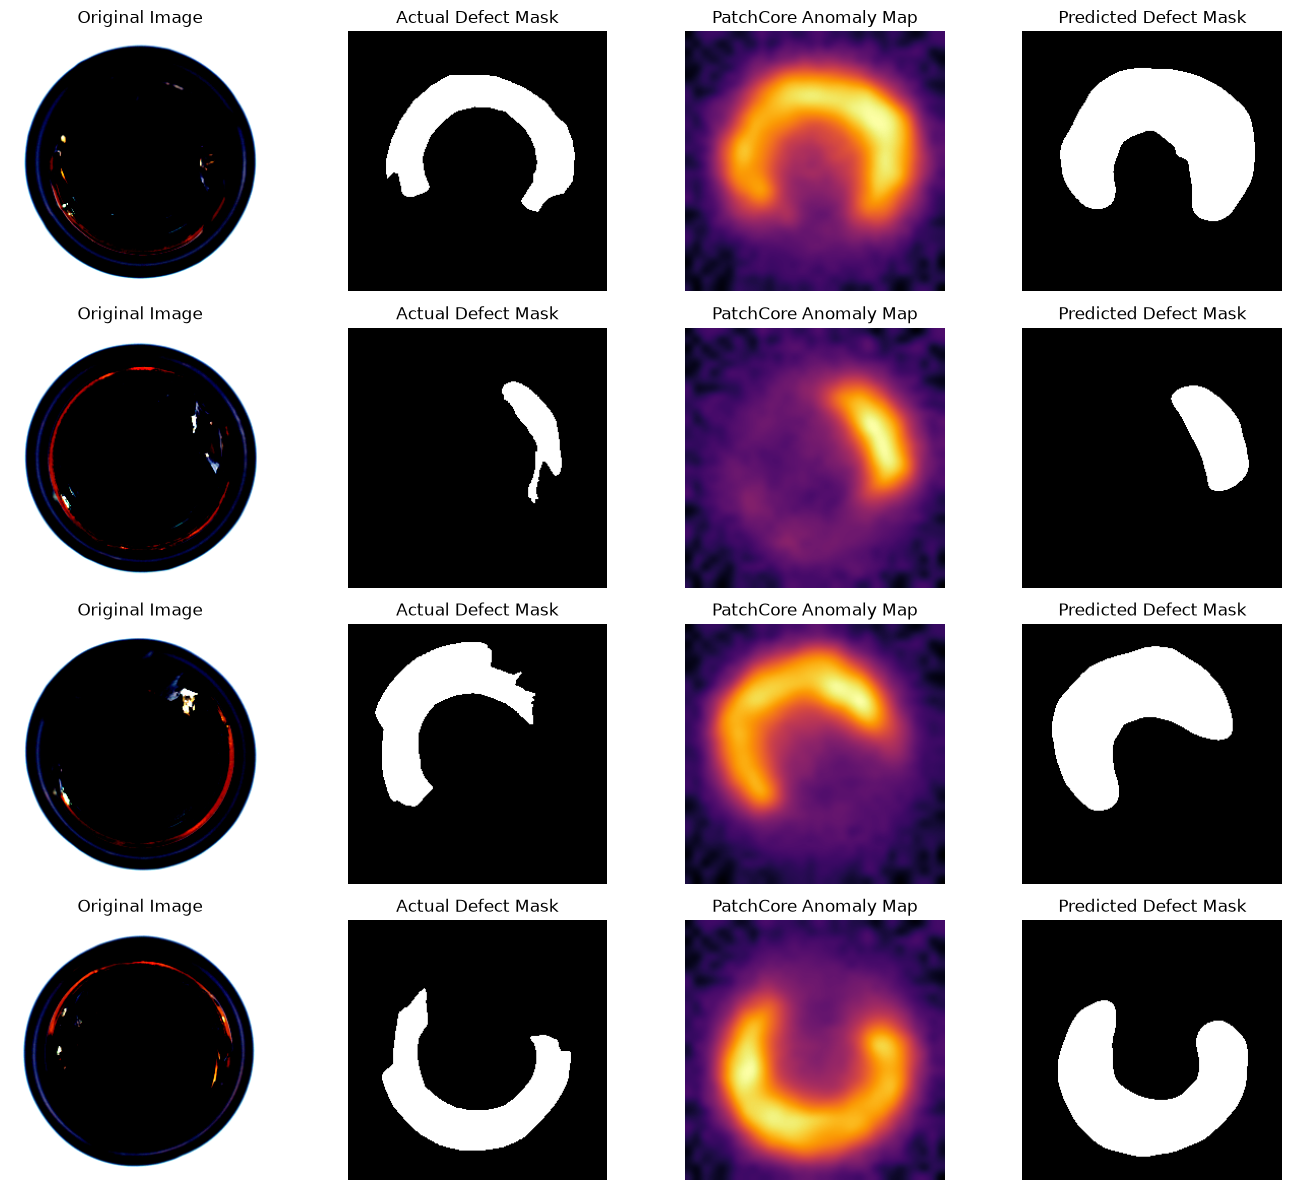

In [27]:
import matplotlib.pyplot as plt

first_prediction = predictions[0]

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for i in range(4):
    image = first_prediction.image[i].detach().cpu().permute(1, 2, 0).numpy()
    gt_mask = first_prediction.gt_mask[i].detach().cpu().numpy()
    anomaly_map = first_prediction.anomaly_map[i].detach().cpu().numpy()
    pred_mask = first_prediction.pred_mask[i].detach().cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(gt_mask, cmap="gray")
    axes[i, 1].set_title("Actual Defect Mask")

    axes[i, 2].imshow(anomaly_map, cmap="inferno")
    axes[i, 2].set_title("PatchCore Anomaly Map")

    axes[i, 3].imshow(pred_mask, cmap="gray")
    axes[i, 3].set_title("Predicted Defect Mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

Visualisation across the full test set

In [28]:
for batch_idx, batch in enumerate(predictions):
    print(
        f"Batch {batch_idx + 1}:",
        "Images =", batch.image.shape[0],
        "| Scores =", batch.pred_score.detach().cpu().numpy().round(3),
        "| Labels =", batch.pred_label.detach().cpu().numpy(),
        "| Actual =", batch.gt_label.detach().cpu().numpy(),
    )

Batch 1: Images = 8 | Scores = [0.937 0.83  1.    0.89  0.996 0.908 0.785 0.988] | Labels = [ True  True  True  True  True  True  True  True] | Actual = [ True  True  True  True  True  True  True  True]
Batch 2: Images = 8 | Scores = [0.896 0.986 0.891 0.973 1.    0.926 1.    0.795] | Labels = [ True  True  True  True  True  True  True  True] | Actual = [ True  True  True  True  True  True  True  True]
Batch 3: Images = 8 | Scores = [0.836 0.854 0.898 1.    1.    1.    0.907 0.764] | Labels = [ True  True  True  True  True  True  True  True] | Actual = [ True  True  True  True  True  True  True  True]
Batch 4: Images = 8 | Scores = [1.    0.882 1.    0.58  0.943 1.    0.541 0.569] | Labels = [ True  True  True  True  True  True  True  True] | Actual = [ True  True  True  True  True  True  True  True]
Batch 5: Images = 8 | Scores = [0.172 0.276 0.217 0.178 0.234 0.213 0.187 0.182] | Labels = [False False False False False False False False] | Actual = [False False False False False Fals

Saving the trained model

In [29]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "Projects" / "VisionQC"
MODEL_DIR = PROJECT_ROOT / "models" / "patchcore"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR)

Model directory: /Users/anupamguptaroy17/Projects/VisionQC/models/patchcore


Saving PatchCore model and its memory bank

In [30]:
import inspect

print("Engine export method:")
print(inspect.signature(engine.export))

print("\nPatchCore save-related methods:")
print([
    name for name in dir(model)
    if any(word in name.lower() for word in ["save", "export", "checkpoint"])
])

Engine export method:
(model: anomalib.models.components.base.anomalib_module.AnomalibModule, export_type: anomalib.deploy.export.ExportType | str, export_root: str | pathlib.Path | None = None, model_file_name: str = 'model', input_size: tuple[int, int] | None = None, compression_type: anomalib.deploy.export.CompressionType | None = None, datamodule: anomalib.data.datamodules.base.image.AnomalibDataModule | None = None, metric: torchmetrics.metric.Metric | str | None = None, max_drop: float = 0.01, ov_args: dict[str, typing.Any] | None = None, ov_kwargs: dict[str, typing.Any] | None = None, onnx_kwargs: dict[str, typing.Any] | None = None, ckpt_path: str | pathlib.Path | None = None) -> pathlib.Path | None

PatchCore save-related methods:
['CHECKPOINT_HYPER_PARAMS_KEY', 'CHECKPOINT_HYPER_PARAMS_NAME', 'CHECKPOINT_HYPER_PARAMS_TYPE', '_checkpointable_components', '_save_to_state_dict', 'checkpoint_safe_globals', 'load_from_checkpoint', 'on_load_checkpoint', 'on_save_checkpoint', 'save_

Verifying the local checkpoint

In [31]:
from pathlib import Path

checkpoint_path = (
    PROJECT_ROOT
    / "notebooks"
    / "results"
    / "Patchcore"
    / "VisionQC_Bottle"
    / "v2"
    / "weights"
    / "lightning"
    / "model.ckpt"
)

print("Checkpoint exists:", checkpoint_path.exists())

if checkpoint_path.exists():
    print(f"Checkpoint size: {checkpoint_path.stat().st_size / (1024**2):.2f} MB")
    print("Checkpoint path:", checkpoint_path)

Checkpoint exists: True
Checkpoint size: 220.50 MB
Checkpoint path: /Users/anupamguptaroy17/Projects/VisionQC/notebooks/results/Patchcore/VisionQC_Bottle/v2/weights/lightning/model.ckpt


Checking available Export types for our PatchCore Model

In [32]:
from anomalib.deploy import ExportType

print("Available export types:")
print(list(ExportType))

Available export types:
[<ExportType.ONNX: 'onnx'>, <ExportType.OPENVINO: 'openvino'>, <ExportType.TORCH: 'torch'>]


Exporting the model now

In [33]:
from anomalib.deploy import ExportType

export_path = engine.export(
    model=model,
    export_type=ExportType.TORCH,
    export_root=MODEL_DIR,
    model_file_name="visionqc_patchcore",
    input_size=(256, 256),
)

print("Export path:", export_path)

Export path: /Users/anupamguptaroy17/Projects/VisionQC/models/patchcore/weights/torch/visionqc_patchcore.pt


Allowing loading the trusted export

In [34]:
import os

os.environ["TRUST_REMOTE_CODE"] = "1"

from anomalib.deploy import TorchInferencer

inferencer = TorchInferencer(
    path=export_path,
    device="cpu",
)

print("TorchInferencer loaded successfully!")

TorchInferencer loaded successfully!


Inspecting the prediction method before running inference

In [35]:
import inspect

print(inspect.signature(inferencer.predict))

(image: str | pathlib.Path | numpy.ndarray | PIL.Image.Image | torch.Tensor) -> anomalib.data.dataclasses.torch.image.ImageBatch


Testing with one normal bottle image first

In [37]:
from pathlib import Path

normal_image = next(
    (Path("..") / "data/raw/mvtec-ad/bottle/test/good").glob("*.png")
)

print("Image found:", normal_image)

result = inferencer.predict(image=normal_image)

print("Prediction score:", result.pred_score)
print("Prediction label:", result.pred_label)
print("Anomaly map shape:", result.anomaly_map.shape)

Image found: ../data/raw/mvtec-ad/bottle/test/good/002.png
Prediction score: tensor([0.2998])
Prediction label: tensor([False])
Anomaly map shape: torch.Size([1, 256, 256])


Testing for Defective bottle

In [38]:
from pathlib import Path

defect_image = next(
    (Path("..") / "data/raw/mvtec-ad/bottle/test/broken_small").glob("*.png")
)

print("Defective image:", defect_image)

defect_result = inferencer.predict(image=defect_image)

print("Prediction score:", defect_result.pred_score)
print("Prediction label:", defect_result.pred_label)
print("Anomaly map shape:", defect_result.anomaly_map.shape)

Defective image: ../data/raw/mvtec-ad/bottle/test/broken_small/002.png
Prediction score: tensor([0.9777])
Prediction label: tensor([True])
Anomaly map shape: torch.Size([1, 256, 256])


Visualising the anomaly map

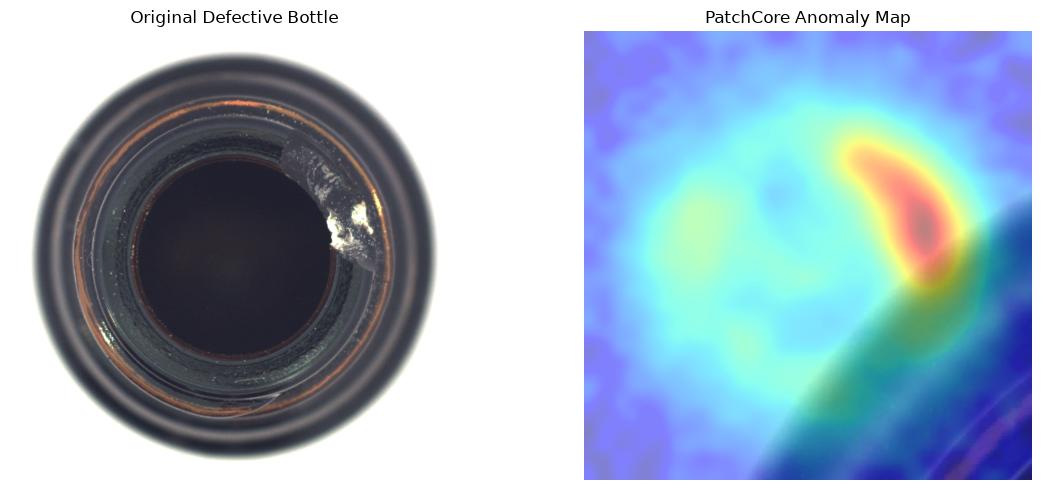

In [39]:
import matplotlib.pyplot as plt
import numpy as np

image = plt.imread(defect_image)
anomaly_map = defect_result.anomaly_map[0].cpu().numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Defective Bottle")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(anomaly_map, alpha=0.5, cmap="jet")
plt.title("PatchCore Anomaly Map")
plt.axis("off")

plt.tight_layout()
plt.show()

Evaluating the exported model across the full test set

In [40]:
# First we gathered all the test images and their corresponding true labels (0 for normal, 1 for defective) from the MVTec dataset. This allows us to evaluate the performance of our trained PatchCore model on a variety of test cases, including both normal and defective bottles.
from pathlib import Path

test_root = Path("../data/raw/mvtec-ad/bottle/test")

normal_images = list((test_root / "good").glob("*.png"))

defect_images = (
    list((test_root / "broken_small").glob("*.png"))
    + list((test_root / "broken_large").glob("*.png"))
    + list((test_root / "contamination").glob("*.png"))
)

test_images = normal_images + defect_images

# 0 = normal, 1 = defective
true_labels = [0] * len(normal_images) + [1] * len(defect_images)

print("Normal images:", len(normal_images))
print("Defective images:", len(defect_images))
print("Total test images:", len(test_images))

Normal images: 20
Defective images: 63
Total test images: 83


In [41]:
# Now we run inference on all test images.
import torch
from tqdm.auto import tqdm

predicted_labels = []
prediction_scores = []

for image_path in tqdm(test_images, desc="Evaluating VisionQC"):
    result = inferencer.predict(image=image_path)

    predicted_labels.append(int(result.pred_label[0].item()))
    prediction_scores.append(float(result.pred_score[0].item()))

print("Inference completed!")
print("Total predictions:", len(predicted_labels))

Evaluating VisionQC:   0%|          | 0/83 [00:00<?, ?it/s]

Inference completed!
Total predictions: 83


Calculating the evaluation metrics

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

y_true = true_labels
y_pred = predicted_labels

print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred), 4))
print("Recall   :", round(recall_score(y_true, y_pred), 4))
print("F1-score :", round(f1_score(y_true, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Defective"],
))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Confusion Matrix:
[[20  0]
 [ 0 63]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        20
   Defective       1.00      1.00      1.00        63

    accuracy                           1.00        83
   macro avg       1.00      1.00      1.00        83
weighted avg       1.00      1.00      1.00        83



Calculating the ROC-AUC Values

In [43]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(true_labels, prediction_scores)

print("Image-level ROC-AUC:", round(roc_auc, 4))

Image-level ROC-AUC: 1.0
